In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Preparing Test Dataset**

In [ ]:
import os
import cv2
import numpy as np
from random import sample

In [ ]:
training_data_path = "/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images"
categories = ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferate_DR']
num_images_per_category = 100

image_paths = []
labels = []


for category in categories:
    category_path = os.path.join(training_data_path, category)
    images_in_category = os.listdir(category_path)
    sampled_images = sample(images_in_category, num_images_per_category)

    for image_name in sampled_images:
        image_path = os.path.join(category_path, image_name)
        image_paths.append(image_path)
        labels.append(categories.index(category))


print(image_paths[5])
print(image_paths[120])
print(image_paths[240])
print(image_paths[360])
print(image_paths[480])

images = []
for image_path in image_paths:
    image = cv2.imread(image_path)
    # Resize the image if needed
    # image = cv2.resize(image, (224, 224))  # Assuming you need images of size 224x224
    images.append(image)

images = np.array(images)
labels = np.array(labels)

/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images/No_DR/0212dd31f623.png
/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images/Mild/5b068765e846.png
/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images/Moderate/c4e8b1ec8893.png
/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images/Severe/07a0e34c8d20.png
/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images/Proliferate_DR/d1a24527a15d.png


In [ ]:
# Shuffle the images and labels in unison
shuffled_indices = np.random.permutation(len(images))
shuffled_images = images[shuffled_indices]
shuffled_labels = labels[shuffled_indices]

# Save the shuffled images and labels to .npy files
np.save('/content/drive/MyDrive/FinalTestDataset/test_images.npy', shuffled_images)
np.save('/content/drive/MyDrive/FinalTestDataset/test_labels.npy', shuffled_labels)

In [ ]:
for i in range (0,5):
  #
  print(shuffled_labels[i])

1
1
2
0
2


#**Load the dataset**

In [ ]:
x_test = np.load('/content/drive/MyDrive/FinalTestDataset/test_images.npy')
y_test = np.load('/content/drive/MyDrive/FinalTestDataset/test_labels.npy')

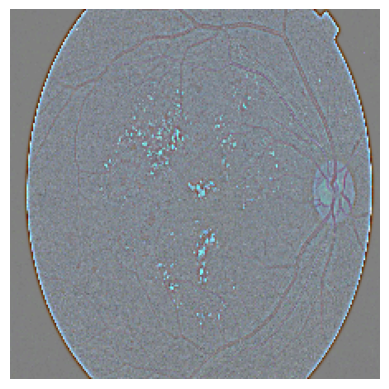

In [ ]:
# you can visualize the first image using Matplotlib
import matplotlib.pyplot as plt

plt.imshow(x_test[49])
plt.axis('off')
plt.show()

In [ ]:
y_test_binary = (y_test > 0).astype(int)

# **InceptionV3**

## **Load the Models:**


In [ ]:
from tensorflow.keras.models import load_model
import pandas as pd
import numpy as np

model1 = load_model('/content/drive/MyDrive/Models/my_model.keras')
print(model1.summary())
#model2 = load_model('model2.h5')
#model3 = load_model('model3.h5')

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 inception_v3 (Functional)   (None, 5, 5, 2048)        21802784  
                                                                 
 global_average_pooling2d_1  (None, 2048)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dropout_1 (Dropout)         (None, 2048)              0         
                                                                 
 dense_1 (Dense)             (None, 5)                 10245     
                                                                 
Total params: 21813029 (83.21 MB)
Trainable params: 21778597 (83.08 MB)
Non-trainable params: 34432 (134.50 KB)
_________________________________________________________________
None


In [ ]:
# Identify the input shape from the summary
input_shape = model1.layers[0].input_shape  # Assuming the input layer is the first layer
print("Input Shape:", input_shape)

Input Shape: (None, 224, 224, 3)


## **Load the Test Data:**

In [ ]:
test_df = pd.read_csv('/content/drive/MyDrive/aptos2019-blindness-detection/test.csv')
X_test = np.load('/content/drive/My Drive/aptos2019-blindness-detection/x_train.npy')

In [ ]:
# Print the shape of the loaded array to understand its dimensions
print("Loaded array shape:", X_test.shape)

# Optionally, print the first few elements or a specific image in the array
print("First image pixel values:")
print(X_test[0])

Loaded array shape: (3662, 224, 224, 3)
First image pixel values:
[[[3 1 2]
  [3 1 2]
  [2 2 2]
  ...
  [2 1 2]
  [2 0 1]
  [3 1 2]]

 [[3 1 2]
  [3 1 1]
  [1 1 1]
  ...
  [2 2 2]
  [2 0 1]
  [3 0 1]]

 [[2 2 2]
  [1 2 2]
  [2 0 1]
  ...
  [1 1 1]
  [1 1 1]
  [2 2 2]]

 ...

 [[2 2 2]
  [1 1 1]
  [2 2 2]
  ...
  [2 2 2]
  [1 1 1]
  [2 2 2]]

 [[1 1 1]
  [2 2 2]
  [1 1 1]
  ...
  [1 1 1]
  [1 1 1]
  [1 1 1]]

 [[3 1 2]
  [1 1 1]
  [1 1 1]
  ...
  [2 2 2]
  [1 1 1]
  [2 2 2]]]


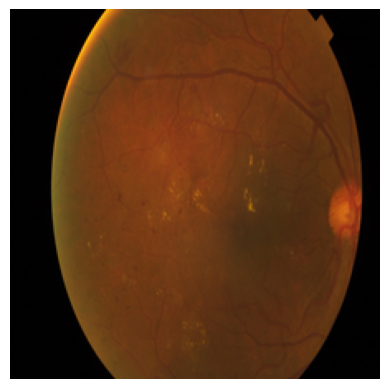

In [ ]:
# you can visualize the first image using Matplotlib
import matplotlib.pyplot as plt

plt.imshow(X_test[0])
plt.axis('off')
plt.show()

In [ ]:
X_test_500i = X_test[1000:1500]

In [ ]:
print("Loaded array shape:", X_test_500i.shape)

Loaded array shape: (500, 224, 224, 3)


## **Make Predictions:**


In [ ]:
# Make predictions on the test data
y_pred = model1.predict(X_test_500i)

16/16 [==============================] - 9s 306ms/step


In [ ]:
print(y_pred)

[[9.9943382e-01 9.9953556e-01 9.9966717e-01 5.2196061e-04 9.7543641e-05]
 [9.9848109e-01 9.9934882e-01 9.9278235e-01 5.0479704e-01 1.3276924e-01]
 [9.9992001e-01 1.8471971e-07 3.4259426e-07 7.5714988e-06 2.9574912e-05]
 ...
 [9.9934858e-01 2.3846370e-04 2.9365686e-04 1.6077169e-03 6.7774847e-04]
 [9.9767452e-01 9.9563450e-01 9.0788770e-01 8.3711885e-02 4.8987415e-02]
 [9.9953091e-01 4.2308457e-05 7.9236510e-05 6.2390842e-05 1.2677570e-04]]


In [ ]:
# Set threshold
threshold = 0.5

# Apply thresholding
y_pred_thresholded = np.where(y_pred >= threshold, 1, 0)

print(y_pred_thresholded)
print(y_pred_thresholded.shape)


[[1 1 1 0 0]
 [1 1 1 1 0]
 [1 0 0 0 0]
 ...
 [1 0 0 0 0]
 [1 1 1 0 0]
 [1 0 0 0 0]]
(500, 5)


In [ ]:
sum_minus_one = np.sum(y_pred_thresholded, axis=1) - 1
print(sum_minus_one)

[2 3 0 0 0 2 0 0 0 2 2 2 2 0 0 1 0 2 1 0 1 0 0 0 3 4 2 1 3 0 0 0 2 2 0 1 4
 2 0 2 0 0 4 4 0 1 0 0 4 2 0 2 0 2 2 4 0 0 0 0 4 0 1 0 0 1 2 0 3 0 3 0 0 0
 2 3 1 0 3 0 0 4 0 0 2 0 0 2 0 2 0 3 1 4 1 2 2 4 0 0 1 4 0 1 3 1 0 0 2 0 0
 1 2 1 0 0 0 0 0 1 2 2 2 0 1 3 2 2 0 2 0 1 1 0 0 2 3 0 0 0 0 0 0 0 0 1 1 0
 0 4 0 2 0 0 2 2 1 0 3 1 2 2 2 2 4 0 0 4 0 0 4 0 2 2 2 2 3 0 0 3 1 1 2 2 2
 0 2 0 0 2 2 2 0 0 0 0 1 2 0 0 2 1 0 0 2 0 1 0 1 3 0 0 0 1 0 0 4 0 0 0 1 2
 2 0 0 2 0 2 2 0 2 2 0 1 0 0 1 4 0 2 1 0 1 0 2 1 0 2 0 0 2 4 2 1 1 0 2 0 2
 0 0 2 0 0 1 1 2 2 0 2 1 0 0 0 4 0 1 0 0 2 2 1 0 0 0 0 0 2 0 1 2 1 4 2 1 0
 2 0 0 2 2 0 2 0 0 0 1 1 0 0 2 0 0 3 0 4 2 1 4 1 0 0 0 4 0 0 0 2 4 0 2 0 0
 0 1 0 2 1 0 2 2 0 0 0 0 4 0 0 0 2 4 0 2 0 0 2 2 2 4 0 0 0 3 0 2 1 3 0 0 0
 2 0 1 3 0 3 0 0 2 0 2 4 0 0 4 4 1 0 0 0 2 4 0 2 4 1 2 0 0 0 2 4 4 2 3 0 0
 1 3 0 0 2 2 2 0 1 0 2 1 0 1 4 0 0 2 0 2 0 1 2 0 0 4 0 1 4 0 0 2 2 2 1 2 0
 0 0 4 0 0 4 1 0 0 0 0 4 0 4 0 2 0 4 0 1 2 0 2 4 0 2 0 1 2 2 3 3 0 1 1 2 2
 0 0 1 2 2 0 0 1 0 0 2 3 

In [ ]:
# Load data from CSV file into a DataFrame
df = pd.read_csv('/content/drive/MyDrive/aptos2019-blindness-detection/EnsembleTestingData/testing_data_wLabels.csv')

In [ ]:
print(df)

          id_code  diagnosis
0    47d1603a555b          1
1    47e51065b819          2
2    4818672273af          2
3    482088e6be44          0
4    4826d10030b3          0
..            ...        ...
495  68987fb159ab          0
496  68ddb15a74de          0
497  691eeb59b4cb          0
498  692e946b1f85          0
499  69591ebb198d          2

[500 rows x 2 columns]


In [ ]:
labels_array = df['diagnosis'].values

print(labels_array)

[1 2 2 0 0 0 2 0 0 0 2 2 2 2 0 0 1 0 2 1 0 1 0 0 0 3 4 2 1 2 0 0 0 2 2 0 1
 4 2 0 2 0 0 4 4 0 1 0 0 4 2 0 2 0 2 2 3 0 0 0 0 4 0 1 0 0 1 2 0 3 0 3 0 0
 0 2 3 1 0 4 0 0 2 0 0 2 0 0 2 0 2 0 3 1 3 1 2 2 4 0 0 1 4 0 1 3 1 0 0 2 0
 0 1 2 1 0 0 0 0 0 1 2 2 2 0 1 3 2 2 0 2 0 1 1 0 0 3 3 0 0 0 0 0 0 0 0 1 1
 0 0 3 0 2 0 0 2 2 1 0 3 1 2 2 2 2 4 0 0 4 0 0 4 0 2 2 2 2 3 0 0 2 2 1 2 2
 2 0 2 0 0 2 2 2 0 0 0 0 1 2 0 0 2 1 0 0 2 0 1 0 1 3 0 0 0 1 0 0 2 0 0 0 1
 2 2 0 0 2 0 2 2 0 2 2 0 1 0 0 1 4 0 2 1 0 1 0 2 1 0 2 0 0 2 4 2 1 1 0 2 0
 2 0 0 2 0 0 1 1 2 2 0 1 1 0 0 0 4 0 1 0 0 2 2 1 0 0 0 0 0 2 0 1 2 2 4 2 1
 0 2 0 0 2 2 0 2 0 0 0 1 1 0 0 2 0 0 3 0 4 2 1 4 1 0 0 0 4 0 0 0 2 4 0 2 0
 0 0 1 0 2 2 0 2 2 0 0 0 0 4 0 0 0 2 4 0 2 0 0 2 2 2 4 0 0 0 2 0 2 1 3 0 0
 0 2 0 1 3 0 3 0 0 2 0 2 4 0 0 4 4 1 0 1 0 3 4 0 2 4 1 2 0 0 0 4 4 4 2 3 0
 0 1 2 0 0 2 2 2 0 1 0 2 1 0 1 4 0 0 2 0 2 0 1 2 0 0 4 0 1 4 0 0 2 2 2 1 2
 0 0 0 4 0 0 4 1 2 0 0 0 4 0 4 0 2 0 4 0 1 2 0 2 4 0 2 0 1 2 2 3 2 0 1 1 2
 2 0 0 1 2 2 0 0 1 0 0 2 

In [ ]:
# Convert multiclass labels to binary
binary_predicted_labels = (sum_minus_one > 0).astype(int)
binary_actual_labels = (labels_array > 0).astype(int)

In [ ]:
y_pred_incep = binary_predicted_labels

In [ ]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(binary_predicted_labels, binary_actual_labels)

print("Accuracy:", accuracy)

Accuracy: 0.482


# **CNN Model**

##Loading data



In [ ]:
from tensorflow.keras.models import load_model
import pandas as pd
import numpy as np

model_cnn = load_model('/content/drive/MyDrive/Models/64x3-CNNwithSVM.h5')

In [ ]:
print(model_cnn.summary())

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 134, 134, 3)          0         ['input_2[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 64, 64, 64)           9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 64, 64, 64)           256       ['conv1_conv[0][0]']          
 on)                                                                                        

In [ ]:
input_shape_CNN = model_cnn.input_shape
print("Input Shape:", input_shape_CNN)

output_shape_CNN = model_cnn.output_shape
print("Output Shape:", output_shape_CNN)

Input Shape: (None, 128, 128, 3)
Output Shape: (None, 5)


## Preprocessing for CNN


In [ ]:
import cv2

resized_images = []
for image in x_test:
    resized_image = cv2.resize(image, (128, 128))
    resized_images.append(resized_image)

resized_images_array = np.array(resized_images)

x_test_CNN = resized_images_array / 255.0


In [ ]:
print(x_test_CNN.shape)

(500, 128, 128, 3)


##Predictions

In [ ]:
y_pred_CNN = model1.predict(x_test_CNN)
print(y_pred_CNN[1])

ValueError: Input 0 of layer "sequential_1" is incompatible with the layer: expected shape=(None, 224, 224, 3), found shape=(32, 128, 128, 3)

In [ ]:
# Convert predicted probabilities to class labels
y_pred_CNN = np.argmax(y_pred_CNN, axis=1)

# Convert multiclass labels to binary
y_pred_CNN = (y_pred_CNN > 0).astype(int)

# **Parallel CNN + MobileNet**

## Installing prerequisites

In [ ]:
from tensorflow.keras.models import load_model
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
model_parallelCNN = load_model('/content/drive/MyDrive/Models/parallel_cnn_model_new(93%).h5')
print(model_parallelCNN.summary())

input_shape = model_parallelCNN.input_shape
print("Input Shape:", input_shape)

output_shape = model_parallelCNN.output_shape
print("Output Shape:", output_shape)

## Preprocessing data

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.utils import resample
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load MobileNetV2 model
mobilenet_model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg', input_shape=(128, 128, 3))

In [ ]:
def extract_mobilenet_features_for_test(img_array):
    img_array = img_array.astype('float32') / 255.0  # Normalize pixel values to [0, 1]
    img_array = cv2.resize(img_array, (128, 128))  # Resize image to 128x128
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = preprocess_input(img_array)  # Preprocess input for MobileNetV2
    features = mobilenet_model.predict(img_array)
    return features[0]


In [ ]:
test_features = []
for img_array in x_test:
    features = extract_mobilenet_features_for_test(img_array)
    test_features.append(features)
x_test_parallelCNN = np.array(test_features)

In [ ]:
print(x_test_parallelCNN.shape)
print(x_test_parallelCNN)

##Predictions

In [ ]:
# Perform predictions on X_test
y_pred_parallelCNN = model_parallelCNN.predict(x_test_parallelCNN)

In [ ]:
print(y_pred_parallelCNN[10])

In [ ]:
# Convert predicted probabilities to class labels
y_pred_parallelCNN = np.argmax(y_pred_parallelCNN, axis=1)

# Convert multiclass labels to binary
y_pred_parallelCNN = (y_pred_CNN > 0).astype(int)

#**Vision Transformer**


## Loading models and data

In [ ]:
!pip install -qq einops
!pip install -qq torchsummary
!pip install scikit-learn

import os
import cv2

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

import albumentations as A
from albumentations.pytorch import ToTensorV2

import matplotlib.pyplot as plt
from tqdm import tqdm

from torch import nn
from torch import Tensor
from torch.utils.data import Subset

from PIL import Image
import pandas as pd
import numpy as np

from torchvision.transforms import Compose, Resize, ToTensor
from torch.optim.lr_scheduler import StepLR
import torch.optim as optim

from einops import rearrange, reduce, repeat
from einops.layers.torch import Rearrange, Reduce

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 1.0 MB/s eta 0:00:00


In [ ]:
class RetinopathyDataset(Dataset):
    def __init__(self, path, transform=None):
        self.img_paths = list(self.absolute_paths(path))
        self.transform = transform
        png_ext = '.png'
        self.paths = [p for p in self.img_paths if png_ext in p]
        self.df = pd.read_csv('/content/drive/MyDrive/DR_224x224_Gaussian Filtered/train.csv')
        self.df = shuffle(self.df)

    def absolute_paths(self, directory):
        for dirpath,_,filenames in os.walk(directory):
            for f in filenames:
                yield os.path.abspath(os.path.join(dirpath, f))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        id_code = self.df.iloc[idx].id_code
        diagnosis = self.df.iloc[idx].diagnosis

        img_path = [s for s in self.paths if id_code in s][0]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform is not None:
            image = self.transform(image=image)["image"]

        return image, diagnosis


train_transform = A.Compose(
    [
        A.SmallestMaxSize(max_size=224),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
        A.RGBShift(r_shift_limit=15, g_shift_limit=15, b_shift_limit=15, p=0.5),
        A.RandomBrightnessContrast(p=0.5),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ]
)


val_transform = A.Compose(
    [
        A.SmallestMaxSize(max_size=224),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ]
)


path = '/content/drive/MyDrive/DR_224x224_Gaussian Filtered/gaussian_filtered_images/gaussian_filtered_images'


rds_train = RetinopathyDataset(path, train_transform)
rds_val = RetinopathyDataset(path, val_transform)

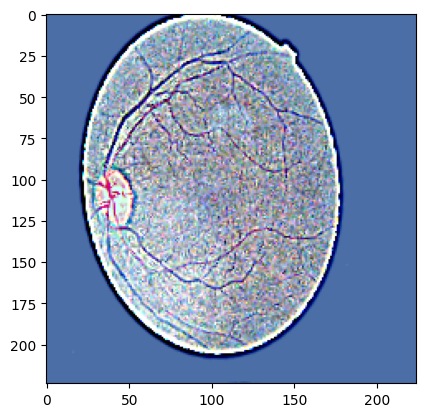

In [ ]:
plt.imshow(rds_train[0][0].permute(1, 2, 0))

In [ ]:
train_idx, valid_idx = train_test_split(np.arange(len(rds_train)), shuffle=False, test_size=0.3, random_state=42)
train_subset = Subset(rds_train, train_idx)
valid_subset = Subset(rds_val, valid_idx)

train_loader = DataLoader(train_subset, batch_size=8, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_subset, batch_size=8, shuffle=True, num_workers=0)

## Implementation

In [ ]:
class PatchEmbedding(nn.Module):
    def __init__(self, in_channels: int=3, patch_size: int=16,
                 emb_size: int=768, img_size: int=224):
        self.patch_size = patch_size
        super().__init__()
        self.projection = nn.Sequential(
            # using a conv layer instead of a linear one -> performance gains
            nn.Conv2d(in_channels, emb_size,
                      kernel_size=patch_size, stride=patch_size),
            Rearrange('b e (h) (w) -> b (h w) e'),
        )
        self.cls_token = nn.Parameter(torch.randn(1, 1, emb_size))
        self.positions = nn.Parameter(
                         torch.randn((img_size // patch_size) ** 2 + 1, emb_size))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, _, _, _ = x.shape
        x = self.projection(x)
        cls_tokens = repeat(self.cls_token, '() n e -> b n e', b=b)
        # prepend the cls token to the input
        x = torch.cat([cls_tokens, x], dim=1)
        # add position embedding
        x += self.positions
        return x


class MultiHeadAttention(nn.Module):
    def __init__(self, emb_size: int=768, num_heads: int=8, dropout: float=0):
        super().__init__()
        self.emb_size = emb_size
        self.num_heads = num_heads
        # fuse the queries, keys and values in one matrix
        self.qkv = nn.Linear(emb_size, emb_size * 3)
        self.att_drop = nn.Dropout(dropout)
        self.projection = nn.Linear(emb_size, emb_size)

    def forward(self, x : Tensor, mask: Tensor = None) -> Tensor:
        # split keys, queries and values in num_heads
        qkv = rearrange(self.qkv(x),
                        "b n (h d qkv) -> (qkv) b h n d", h=self.num_heads, qkv=3)
        queries, keys, values = qkv[0], qkv[1], qkv[2]
        # sum up over the last axis
        # batch, num_heads, query_len, key_len
        energy = torch.einsum('bhqd, bhkd -> bhqk', queries, keys)
        if mask is not None:
            fill_value = torch.finfo(torch.float32).min
            energy.mask_fill(~mask, fill_value)

        scaling = self.emb_size ** (1/2)
        att = F.softmax(energy, dim=-1) / scaling
        att = self.att_drop(att)
        # sum up over the third axis
        out = torch.einsum('bhal, bhlv -> bhav ', att, values)
        out = rearrange(out, "b h n d -> b n (h d)")
        out = self.projection(out)
        return out


class ResidualAdd(nn.Module):
    def __init__(self, fn):
        super().__init__()
        self.fn = fn

    def forward(self, x, **kwargs):
        res = x
        x = self.fn(x, **kwargs)
        x += res
        return x


class FeedForwardBlock(nn.Sequential):
    def __init__(self, emb_size: int, expansion: int=4, drop_p: float=0.):
        super().__init__(
            nn.Linear(emb_size, expansion * emb_size),
            nn.GELU(),
            nn.Dropout(drop_p),
            nn.Linear(expansion * emb_size, emb_size),
        )


class TransformerEncoderBlock(nn.Sequential):
    def __init__(self,
                 emb_size: int = 768,
                 drop_p: float = 0.,
                 forward_expansion: int = 4,
                 forward_drop_p: float = 0.,
                 ** kwargs):
        super().__init__(
            ResidualAdd(nn.Sequential(
                nn.LayerNorm(emb_size),
                MultiHeadAttention(emb_size, **kwargs),
                nn.Dropout(drop_p)
            )),
            ResidualAdd(nn.Sequential(
                nn.LayerNorm(emb_size),
                FeedForwardBlock(
                    emb_size, expansion=forward_expansion, drop_p=forward_drop_p),
                nn.Dropout(drop_p)
            )
            ))


class TransformerEncoder(nn.Sequential):
    def __init__(self, depth: int=6, **kwargs):
        super().__init__(*[TransformerEncoderBlock(**kwargs) for _ in range(depth)])


class ClassificationHead(nn.Sequential):
    def __init__(self, emb_size: int=768, n_classes: int=1000):
        super().__init__(
            Reduce('b n e -> b e', reduction='mean'),
            nn.LayerNorm(emb_size),
            nn.Linear(emb_size, n_classes))


class ViT(nn.Sequential):
    def __init__(self,
                in_channels: int = 3,
                patch_size: int = 16,
                emb_size: int = 768,
                img_size: int = 224,
                depth: int = 6,
                n_classes: int = 5,
                **kwargs):
        super().__init__(
            PatchEmbedding(in_channels, patch_size, emb_size, img_size),
            TransformerEncoder(depth, emb_size=emb_size, **kwargs),
            ClassificationHead(emb_size, n_classes)
        )

##Training

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

model_vit = ViT().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_vit.parameters(), lr=3e-5)
scheduler = StepLR(optimizer, step_size=1, gamma=0.7)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

epochs = 50

epoch_losses = np.zeros((epochs, len(train_loader)))
epoch_accuracies = np.zeros((epochs, len(train_loader)))

epoch_val_losses = np.zeros((epochs, len(valid_loader)))
epoch_val_accuracies = np.zeros((epochs, len(valid_loader)))

optimizer = torch.optim.Adam(model_vit.parameters(), lr=1e-5)

for epoch in range(epochs):

    for i, (data, label) in enumerate(train_loader):
        data = data.to(device)
        label = label.to(device)

        output = model_vit(data)
        loss = criterion(output, label)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        acc = (output.argmax(dim=1) == label).float().mean()
        epoch_accuracies[epoch][i] = acc

        epoch_loss = loss.item()  # Get scalar value of the loss
        epoch_losses[epoch][i] = epoch_loss

        print("Epoch:{:3d}, Iteration:{:3d}, loss:{:.4f}, acc:{:.4f}"
              .format(epoch, i, epoch_loss, acc))

    with torch.no_grad():

        for i, (data, label) in enumerate(valid_loader):
            data = data.to(device)
            label = label.to(device)

            val_output = model_vit(data)
            val_loss = criterion(val_output, label)

            acc = (val_output.argmax(dim=1) == label).float().mean()
            epoch_val_accuracies[epoch][i] = acc

            epoch_val_loss = val_loss.item()  # Get scalar value of the loss
            epoch_val_losses[epoch][i] = epoch_val_loss

    # Calculate predictions for training and validation data
    train_predictions = torch.cat([model_vit(data.to(device)).argmax(dim=1) for data, _ in train_loader])
    train_labels = torch.cat([label for _, label in train_loader])
    val_predictions = torch.cat([model_vit(data.to(device)).argmax(dim=1) for data, _ in valid_loader])
    val_labels = torch.cat([label for _, label in valid_loader])

    # Calculate precision, recall, and F1-score
    train_precision = precision_score(train_labels.cpu(), train_predictions.cpu(), average='weighted')
    train_recall = recall_score(train_labels.cpu(), train_predictions.cpu(), average='weighted')
    train_f1 = f1_score(train_labels.cpu(), train_predictions.cpu(), average='weighted')
    val_precision = precision_score(val_labels.cpu(), val_predictions.cpu(), average='weighted')
    val_recall = recall_score(val_labels.cpu(), val_predictions.cpu(), average='weighted')
    val_f1 = f1_score(val_labels.cpu(), val_predictions.cpu(), average='weighted')

    print("Epoch:{:3d}, Train_loss:{:.4f}, Train_acc:{:.4f}, Val_loss:{:.4f}, Val_acc:{:.4f}, "
          "Train Precision:{:.4f}, Train Recall:{:.4f}, Train F1-score:{:.4f}, "
          "Val Precision:{:.4f}, Val Recall:{:.4f}, Val F1-score:{:.4f}"
          .format(epoch, epoch_losses[epoch].mean(),
                  epoch_accuracies[epoch].mean(),
                  epoch_val_losses[epoch].mean(),
                  epoch_val_accuracies[epoch].mean(),
                  train_precision, train_recall, train_f1,
                  val_precision, val_recall, val_f1))

Epoch:  0, Iteration:  0, loss:1.6270, acc:0.5000
Epoch:  0, Iteration:  1, loss:1.8516, acc:0.2500
Epoch:  0, Iteration:  2, loss:1.1317, acc:0.7500
Epoch:  0, Iteration:  3, loss:1.6885, acc:0.3750
Epoch:  0, Iteration:  4, loss:1.2774, acc:0.6250
Epoch:  0, Iteration:  5, loss:1.5571, acc:0.3750
Epoch:  0, Iteration:  6, loss:1.1464, acc:0.5000
Epoch:  0, Iteration:  7, loss:1.1546, acc:0.5000
Epoch:  0, Iteration:  8, loss:1.5855, acc:0.1250
Epoch:  0, Iteration:  9, loss:1.4869, acc:0.2500
Epoch:  0, Iteration: 10, loss:0.7973, acc:0.6250
Epoch:  0, Iteration: 11, loss:1.3792, acc:0.3750
Epoch:  0, Iteration: 12, loss:1.2733, acc:0.3750
Epoch:  0, Iteration: 13, loss:1.8724, acc:0.2500
Epoch:  0, Iteration: 14, loss:1.0206, acc:0.6250
Epoch:  0, Iteration: 15, loss:1.3564, acc:0.3750
Epoch:  0, Iteration: 16, loss:1.6726, acc:0.3750
Epoch:  0, Iteration: 17, loss:2.0415, acc:0.2500
Epoch:  0, Iteration: 18, loss:1.3764, acc:0.5000
Epoch:  0, Iteration: 19, loss:1.4624, acc:0.5000


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Epoch:  0, Train_loss:1.3352, Train_acc:0.4724, Val_loss:1.1981, Val_acc:0.5239, Train Precision:0.3146, Train Recall:0.4869, Train F1-score:0.3408, Val Precision:0.2737, Val Recall:0.5232, Val F1-score:0.3594
Epoch:  1, Iteration:  0, loss:1.1595, acc:0.6250
Epoch:  1, Iteration:  1, loss:1.2071, acc:0.6250
Epoch:  1, Iteration:  2, loss:1.1314, acc:0.3750
Epoch:  1, Iteration:  3, loss:1.4041, acc:0.5000
Epoch:  1, Iteration:  4, loss:1.1123, acc:0.6250
Epoch:  1, Iteration:  5, loss:1.6032, acc:0.2500
Epoch:  1, Iteration:  6, loss:1.5216, acc:0.3750
Epoch:  1, Iteration:  7, loss:1.5977, acc:0.2500
Epoch:  1, Iteration:  8, loss:1.0697, acc:0.7500
Epoch:  1, Iteration:  9, loss:1.5803, acc:0.1250
Epoch:  1, Iteration: 10, loss:1.4782, acc:0.6250
Epoch:  1, Iteration: 11, loss:1.6651, acc:0.5000
Epoch:  1, Iteration: 12, loss:1.5966, acc:0.2500
Epoch:  1, Iteration: 13, loss:0.9322, acc:0.7500
Epoch:  1, Iteration: 14, loss:1.1837, acc:0.6250
Epoch:  1, Iteration: 15, loss:1.4566, a

In [ ]:
def predict(image, device):
    if len(image.shape) == 3:
        image = image.unsqueeze(0)

    label = model_vit(image.to(device))
    label_max = torch.max(label, axis=1)[1].item()
    return label_max

In [ ]:
# try 10 images
for i in range(50):
    image, label = rds_val[i]

    predicted = predict(image, device)
    expected = label
    correct = expected==predicted

    print('{:2d}) Expected:{:1d} - Predicted:{:1d} - Correct:{}'
             .format(i+1, expected, predicted, correct))

##Preprocess test data

In [ ]:
test_transform = A.Compose([
    A.Resize(224, 224),  # Resize to 224x224
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

In [ ]:
transformed_images = []
for image in x_test:
    # Convert to uint8 if necessary
    image = image.astype(np.uint8)
    transformed = test_transform(image=image)['image']
    transformed_images.append(transformed)


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Convert transformed images and labels to PyTorch tensors
transformed_images = torch.stack([torch.tensor(img) for img in transformed_images])
labels_tensor = torch.tensor(labels)

# Create a TensorDataset
test_dataset = TensorDataset(transformed_images, labels_tensor)

# Create a DataLoader for testing
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)


In [ ]:
# Assuming you have already loaded and defined your model and device

model.eval()  # Set model to evaluation mode
predictions = []

for data, label in test_loader:
    data = data.to(device)
    output = model(data)
    predictions.extend(torch.argmax(output, dim=1).tolist())

# Calculate accuracy or perform further analysis


#**Genetic Algorithm**

## Installing dependencies

In [ ]:
!pip install pickle5  # Pickle5 is a faster alternative to the default pickle library
import pickle5 as pickle  # Import pickle5 as pickle


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.1/132.1 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pickle5: filename=pickle5-0.0.11-cp310-cp310-linux_x86_64.whl size=255317 sha256=72aa86f4f75b778ba1e1b15fcd26410c38c5e89f2c7ae96e2c6de644b2cf4dc8
  Stored in directory: /root/.cache/pip/wheels/7d/14/ef/4aab19d27fa8e58772be5c71c16add0426acf9e1f64353235c
Successfully built pickle5


## Genetic Algorithms

In [ ]:
from joblib import load
loaded_model = load('/content/drive/MyDrive/Models/tabeeb.pkl')


In [ ]:
print(type(loaded_model))  # Print the type of the loaded model
#print(loaded_model.predict(x_test))  # Example prediction using the loaded model


<class 'sklearn.svm._classes.SVC'>


In [ ]:
print("SVM Parameters:")
print("Kernel:", loaded_model.kernel)
print("C (regularization parameter):", loaded_model.C)
# Print other relevant parameters as needed


SVM Parameters:
Kernel: poly
C (regularization parameter): 1.0


In [ ]:
print("Number of support vectors:", loaded_model.support_vectors_.shape[0])
print("Support vectors:")
print(loaded_model.support_vectors_)

Number of support vectors: 611
Support vectors:
[[128. 128. 127. ... 129. 128. 128.]
 [129. 126. 128. ... 127. 129. 130.]
 [128. 128. 128. ... 128. 129. 129.]
 ...
 [128. 128. 126. ... 131. 130. 128.]
 [129. 131. 136. ... 124. 124. 125.]
 [129. 127. 133. ... 129. 127. 128.]]


In [ ]:
print("Number of classes:", loaded_model.classes_.shape[0])
print("Coefficients:")
#print(loaded_model.coef_)
print("Intercept:")
print(loaded_model.intercept_)

Number of classes: 5
Coefficients:
Intercept:
[ 0.52511751 -0.45659292 -1.7089027   1.82258578 -1.68361416 -0.29799942
  0.86650961 -1.44961126  2.17984118  4.7535272 ]


In [ ]:
input_features = loaded_model.support_vectors_
print("Input features shape:", input_features.shape)

Input features shape: (611, 24532)


#**Weighted Average Ensembling**

In [ ]:
predictions1 = y_pred_inception
predictions2 = y_pred_cnn
predictions3 = y_pred_parallelCnn

In [ ]:
weights = [0.1, 0.5, 0.4]

# Calculate weighted average prediction
weighted_average = (
    weights[0] * np.array(predictions1) +
    weights[1] * np.array(predictions2) +
    weights[2] * np.array(predictions3)
)

# Convert to binary predictions based on a threshold (e.g., 0.5)
threshold = 0.5
binary_predictions = (weighted_average > threshold).astype(int)

# Calculate accuracy
accuracy = np.mean(binary_predictions == y_test_binary)
print("Accuracy:", accuracy)

Accuracy: 0.784


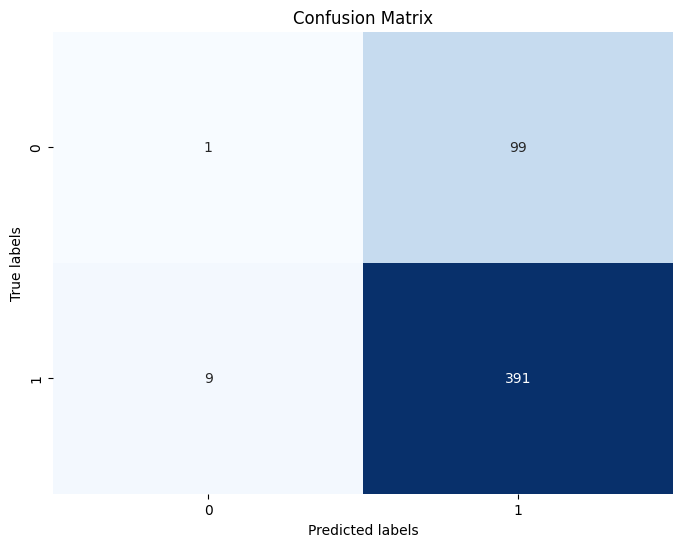

Classification Report:
              precision    recall  f1-score   support

           0       0.10      0.01      0.02       100
           1       0.80      0.98      0.88       400

    accuracy                           0.78       500
   macro avg       0.45      0.49      0.45       500
weighted avg       0.66      0.78      0.71       500



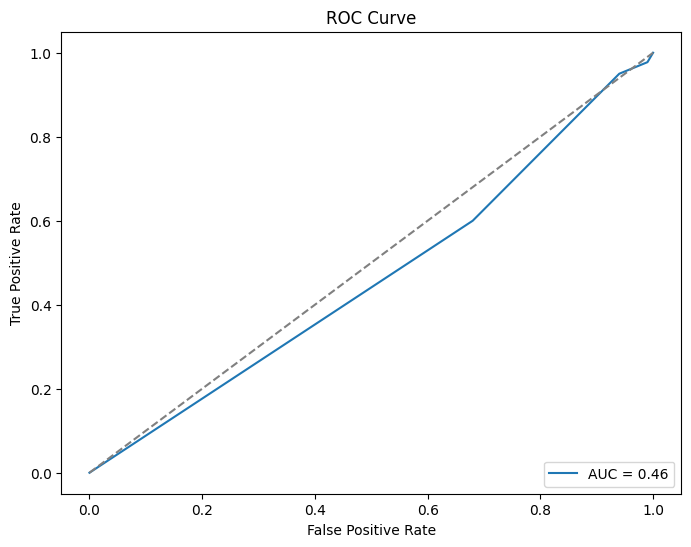

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Assuming binary_predictions and y_test_binary are defined from the previous code

# Calculate confusion matrix
cm = confusion_matrix(y_test_binary, binary_predictions)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate and plot classification report
report = classification_report(y_test_binary, binary_predictions)
print("Classification Report:")
print(report)

# Plot ROC curve and calculate AUC
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test_binary, weighted_average)
roc_auc = roc_auc_score(y_test_binary, weighted_average)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


#**Bagging**

In [ ]:
# Perform majority voting
ensemble_predictions = np.sum([predictions1, predictions2, predictions3], axis=0)
ensemble_predictions = (ensemble_predictions >= 2).astype(int)

Accuracy: 0.786


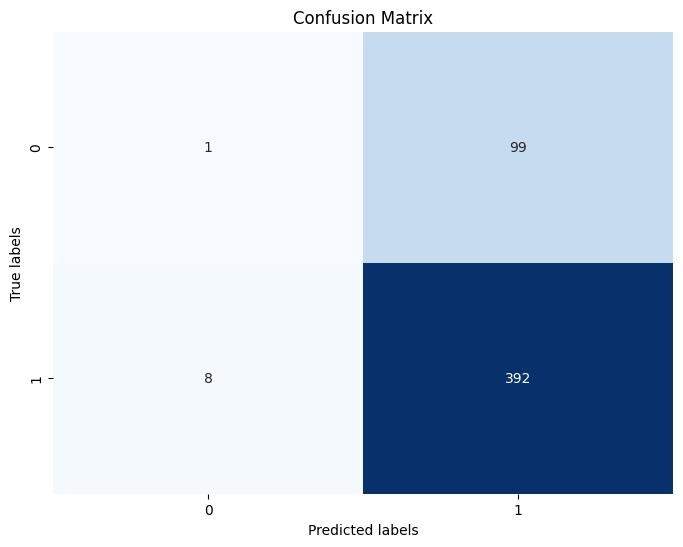

Classification Report:
              precision    recall  f1-score   support

           0       0.10      0.01      0.02       100
           1       0.80      0.98      0.88       400

    accuracy                           0.78       500
   macro avg       0.45      0.49      0.45       500
weighted avg       0.66      0.78      0.71       500



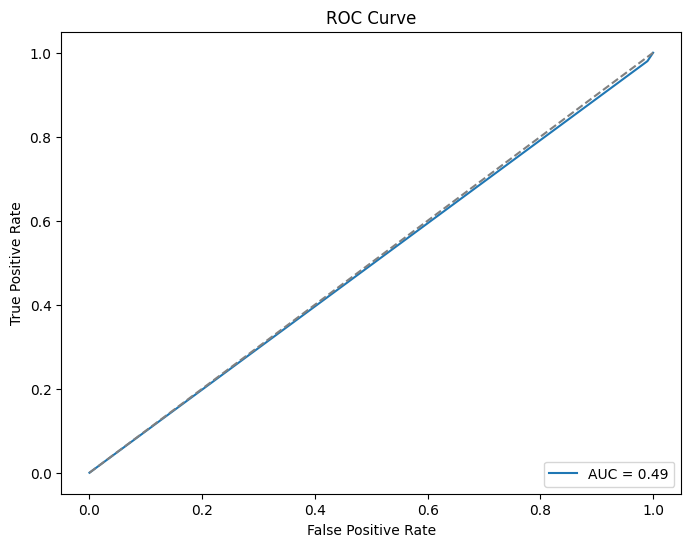

In [ ]:
# Calculate accuracy
accuracy = np.mean(ensemble_predictions == y_test_binary)
print("Accuracy:", accuracy)

# Calculate confusion matrix
cm = confusion_matrix(y_test_binary, ensemble_predictions)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate and plot classification report
report = classification_report(y_test_binary, binary_predictions)
print("Classification Report:")
print(report)

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test_binary, ensemble_predictions)
roc_auc = roc_auc_score(y_test_binary, ensemble_predictions)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()